# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: CHORIPÁN

# Integrantes
* integrante
* integrante

In [16]:
#importamos librerías
import numpy as np
import alc
import pandas as pd
import cv2
from matplotlib import pyplot as plt

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?


Se tiene que $Q \in \mathbb{R}^{2n \times 12}$, por lo que representa una transformación lineal:

$$
Q:\mathbb{R}^{12}\longrightarrow\mathbb{R}^{2n}
$$

Para resolver el sistema homogéneo $Qm=0$ y obtener una solución no nula única salvo un factor de escala, necesitamos que el núcleo de $Q$ tenga dimensión 1:

$$
\dim(\ker(Q))=1
$$

Como la dimensión de la imagen coincide con el rango:

$$
\dim(\operatorname{Im}(Q))=\operatorname{rg}(Q)
$$

Entonces, por el teorema de la dimensión tenemos que:

$$
\dim(\mathbb{R}^{12})=\dim(\ker(Q))+\dim(\operatorname{Im}(Q))
$$

Entonces:

$$
12=1+\operatorname{rg}(Q)
\Longrightarrow \operatorname{rg}(Q)=11
$$

Por lo tanto, necesitamos que $Q$ tenga rango 11 para obtener una solución no nula única salvo escala.

Respecto a la cantidad de puntos necesarios podemos decir que como cada correspondencia entre un punto 3D y uno 2D genera dos filas de $Q$, y sabemos que:

$$
\operatorname{rg}(Q)\leq\min(2n,12)
$$

Como necesitamos que $Q$ tenga rango 11:

$$
11\leq 2n
\Longrightarrow n\geq\frac{11}{2}
\Longrightarrow n\geq6
$$

Entonces, se necesitan al menos 6 puntos.

Por último, la condición que deben cumplir los puntos es que no deben ser todos coplanares, pues si lo son el rango de $Q$ va a ser menor a 11, y la solución no va a ser única salvo un factor escala . Por ejemplo, si pertenecen al plano $W=0$, las columnas de $Q$ que contienen $W_i$, $-u_iW_i$ y $-v_iW_i$ son nulas.

Entonces:

$$
\operatorname{rg}(Q)\leq9<11
$$

Y por el teorema de la dimensión tenemos que:

$$
\dim(\ker(Q))=12-\operatorname{rg}(Q)\geq3
$$

Por lo tanto, el núcleo deja de tener dimensión 1 y la solución deja de ser única salvo un factor escala.

En conclusión, para poder aplicar DLT y conseguir una solución única salvo un factor escala, se necesita que $\operatorname{rg}(Q)=11$, un mínimo de 6 correspondencias entre puntos 3D y 2D, y que los puntos no sean todos coplanares.



Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

Nosotros buscamos resolver el sistema homogéneo $Qm=0$. Sin embargo, cuando trabajamos con datos reales, por ejemplo debido a errores de localización de puntos, puede ocurrir que no exista un vector no nulo que cumpla $Qm=0$.

Por eso buscamos un vector $\mathbf{m}$ que minimice la norma cuadrada de $Qm$, con $\|m\|_2=1$ para evitar la solución trivial $m=0$.

Por lo tanto, vamos a resolver:

$$
\min_{\|m\|_2=1}\|Qm\|_2^2
$$

Partimos de realizar la descomposción SVD de $Q$, entonces:

$$
Q=U\Sigma V^T
$$

Como buscamos $\mathbf{m}$ que minimice $\|Qm\|_2^2$, sujeto a $\|m\|_2=1$ , reemplazando por la SVD, tenemos que:

$$
\|Qm\|_2^2
=\|U\Sigma V^Tm\|_2^2
=\|\Sigma V^Tm\|_2^2
$$

La última igualdad se cumple porque $U$ es ortogonal y, por lo tanto, conserva la norma euclídea.

Si tomamos:

$$
x=V^Tm
$$

Como $Q\in\mathbb{R}^{2n\times12}$ y consideramos $n\geq6$, tenemos que $\min(2n,12)=12$. Por lo tanto, su descomposición SVD tiene 12 valores singulares, contando los que puedan ser nulos.

Entonces, tenemos que:

$$
\|\Sigma x\|_2^2
=
\left\|
\begin{pmatrix}
\sigma_1 & & 0\\
& \ddots &\\
0 & & \sigma_{12}
\end{pmatrix}
\begin{pmatrix}
x_1\\
\vdots\\
x_{12}
\end{pmatrix}
\right\|_2^2
$$
Para simplificar la notación, representamos únicamente la parte diagonal de  $\Sigma$, ya que las filas restantes son nulas y no afectan el cálculo de la norma.
 
Por lo tanto:

$$
\|\Sigma x\|_2^2
=
\left\|
\begin{pmatrix}
\sigma_1x_1\\
\vdots\\
\sigma_{12}x_{12}
\end{pmatrix}
\right\|_2^2
=
\sum_{i=1}^{12}\sigma_i^2x_i^2
$$

Como los valores singulares están ordenados de mayor a menor:

$$
\sigma_1\geq\sigma_2\geq\cdots\geq\sigma_{12}\geq0
$$

Tenemos que:

$$
\sum_{i=1}^{12}\sigma_i^2x_i^2
\geq
\sigma_{12}^2\sum_{i=1}^{12}x_i^2
$$

Como $$\|x\|_2^2=\sum_{i=1}^{12}x_i^2$$
Veamos que $\|x\|_2^2=1$:

$$
\|x\|_2^2
=(V^Tm)^T(V^Tm)
$$

$$
=m^TVV^Tm
=m^TIm
=\|m\|_2^2=1
$$

Esto se cumple porque $V$ es ortogonal y porque impusimos $\|m\|_2=1$.

Entonces tenemos que:

$$
\sum_{i=1}^{12}\sigma_i^2x_i^2
\geq
\sigma_{12}^2\sum_{i=1}^{12}x_i^2
=\sigma_{12}^2
$$

Esta cota inferior se alcanza tomando el vector canónico $e_{12}$ , por lo que se tiene $x=e_{12}$ que cumple $\|x\|_2=1$.

Por lo tanto, el mínimo es $\sigma_{12}^2$.

Finalmente, despejamos $m$:

$$
x=V^Tm
$$

Como $V$ es ortogonal:

$$
Vx=VV^Tm=m
$$

Tomando $x=e_{12}$:

$$
m=Ve_{12}=v_{12}
$$

En conclusión, el mínimo de $\|Qm\|_2^2$, sujeto a $\|m\|_2=1$, se alcanza tomando como $m$ el vector singular derecho asociado al menor valor singular de $Q$, es decir, la última columna de $V$.



### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

# Emprolijar explicación 2.C
Para calcular R, t y K a partir de M tomamos que M = K [R | t] = [KR | Kt]. Tomamos M_3 las primeras 3 filas y columnas de M entonces M_3 = KR .teniendo en cuenta que K es triangular superior y R es ortonormal se ve que parece una descomposicion QR invertida. Tomamos la inversa entonces (M_3)^-1 = R^-1 * K^-1 = R^T * K^-1 por R ser ortonormal. Además como K es triangular superior su inversa tambien lo es. Entonces R^T K^-1 es una descomposición QR de M_3^-1 donde R^T = Q y K^-1 es U (U sería la R en la decomp QR)

Además sabemos que M_4 = Kt (M_4 es el vector correspondiente a la cuarta columna de M) entonces tenemos algo de la forma Ax = B, siendo A triangular superior.


Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

#### Resolución 3

**Datos.** En cada vista marcamos a mano las 4 esquinas internas extremas del tablero. En el plano del tablero son $(0, 0)$, $(300, 0)$, $(0, 180)$ y $(300, 180)$ mm, porque las esquinas internas están en $(30i,\ 30j)$ con $i = 0..10$, $j = 0..6$. Quedaron guardadas en $\texttt{p\_corners.txt}$ (mm) y $\texttt{detected\_corners.txt}$ (px, una fila por vista).

En la carpeta $\texttt{calib/coplanar}$ hay 10 imágenes ($\texttt{Im\_R\_1}$ a $\texttt{Im\_R\_10}$), no 20, así que trabajamos con esas 10.

In [17]:
filepath_calib = 'calib/coplanar'

objPts_tablero = np.loadtxt(f'{filepath_calib}/p_corners.txt')
imgPts_vistas = np.loadtxt(f'{filepath_calib}/detected_corners.txt')
print(objPts_tablero)
print(imgPts_vistas.shape)

[[  0.   0.]
 [300.   0.]
 [  0. 180.]
 [300. 180.]]
(10, 8)


**Homografía de cada vista.** Como el tablero es plano ($W = 0$), cada vista queda descripta por una homografía $\mathbf{H}$ de 3×3 con 8 grados de libertad. Cada punto aporta 2 ecuaciones, así que alcanzan 4 puntos sin 3 alineados para que $Q \in \mathbb{R}^{8\times 9}$ tenga rango 8. La calculamos con $\texttt{resolverDLT2D}$ (DLT con normalización de Hartley).

In [18]:
Hs = []
for k in range(imgPts_vistas.shape[0]):
    imgPts_k = imgPts_vistas[k].reshape(-1, 2)
    Hs.append(alc.resolverDLT2D(imgPts_k, objPts_tablero))
print(len(Hs), 'homografías')

10 homografías


**a) Matriz $\mathbf{K}$ (Zhang).** Cada $\mathbf{H} = \lambda \mathbf{K}[\mathbf{r}_1\ \mathbf{r}_2\ \mathbf{t}]$. Como $\mathbf{r}_1$ y $\mathbf{r}_2$ son ortonormales, con $\mathbf{B} = \mathbf{K}^{-T}\mathbf{K}^{-1}$ y $\mathbf{h}_i$ las columnas de $\mathbf{H}$:

$$\mathbf{h}_1^T \mathbf{B}\, \mathbf{h}_2 = 0, \qquad \mathbf{h}_1^T \mathbf{B}\, \mathbf{h}_1 = \mathbf{h}_2^T \mathbf{B}\, \mathbf{h}_2.$$

$\mathbf{B}$ es simétrica, así que tiene 6 incógnitas $\mathbf{b}$, y cada vista da 2 ecuaciones $\mathbf{v}_{12}^T\mathbf{b} = 0$ y $(\mathbf{v}_{11} - \mathbf{v}_{22})^T\mathbf{b} = 0$. Con las 10 vistas armamos $A \in \mathbb{R}^{20\times 6}$ ($\texttt{armarA}$) y resolvemos $\min_{\|\mathbf{b}\|=1} \|A\mathbf{b}\|$.

Después, con Cholesky $\mathbf{B} = \mathbf{L}\mathbf{L}^T$, obtenemos $\mathbf{K} = (\mathbf{L}^T)^{-1}$ y la normalizamos para que $K_{33} = 1$ ($\texttt{calcularMatrizK2D}$). Como $\mathbf{b}$ sale a menos de un signo, si $\mathbf{B}$ no es definida positiva la multiplicamos por $-1$.

In [19]:
A = alc.armarA(Hs)
K = alc.calcularMatrizK2D(A)
print(K)

[[902.74402652   0.93859447 535.001955  ]
 [  0.         918.7361001  284.54069313]
 [  0.           0.           1.        ]]


El centro óptico $(c_u, c_v) \approx (535,\ 285)$ queda cerca del centro de la imagen ($1024 \times 576$ px, centro en $(512,\ 288)$), y $\alpha_u \approx \alpha_v$. El término $K_{12}$ (skew) es chico comparado con las focales.

**b) Pose de $\texttt{Im\_R\_1}$ y $\texttt{Im\_R\_10}$.** De $\mathbf{H} = \lambda\mathbf{K}[\mathbf{r}_1\ \mathbf{r}_2\ \mathbf{t}]$:

$$\lambda = \frac{1}{\|\mathbf{K}^{-1}\mathbf{h}_1\|}, \quad \mathbf{r}_1 = \lambda \mathbf{K}^{-1}\mathbf{h}_1, \quad \mathbf{r}_2 = \lambda \mathbf{K}^{-1}\mathbf{h}_2, \quad \mathbf{r}_3 = \mathbf{r}_1 \times \mathbf{r}_2, \quad \mathbf{t} = \lambda \mathbf{K}^{-1}\mathbf{h}_3$$

($\texttt{obtenerPose2D}$). $\mathbf{t}$ queda en mm, igual que los puntos del tablero. $\texttt{Im\_R\_20}$ no está en la carpeta.

In [20]:
for k in [0, 9]:
    R, t = alc.obtenerPose2D(Hs[k], K)
    print(f'Im_R_{k + 1}')
    print('R =')
    print(R)
    print('t =', t)
    print()

Im_R_1
R =
[[ 0.99952023 -0.01172614 -0.0275736 ]
 [ 0.01423676  0.99777562  0.00866082]
 [ 0.02750683 -0.00898768  0.99746386]]
t = [-120.56426598 -131.36099816  668.4702992 ]

Im_R_10
R =
[[-0.99688397 -0.06839674 -0.03639238]
 [ 0.06166592 -0.9799015   0.19426785]
 [-0.04919006  0.19150013  0.98106585]]
t = [ 106.78764059  143.79615583 -652.2675388 ]



### Ejercicio 4 - Fútbol

a) Calcular la distancia en línea recta, medida sobre el piso, a la que se encuentra Enzo de la línea del arco cuando patea al gol. Para ello, llevar la posición de sus pies de la imagen a la cancha mediante $\mathbf{H}^{-1}$.

#### Resolución 4.a

**Sistema de coordenadas.** Tomamos el sistema del plano $\texttt{estadio\_azteca.png}$: origen en la esquina inferior izquierda, $U$ a lo largo de la cancha ($0$ a $105$ m) y $V$ a lo ancho ($0$ a $68$ m). En la foto, Enzo patea hacia el arco de $U = 0$. Como la cámara mira hacia ese arco desde adentro de la cancha, lo que en la foto está a la izquierda tiene $V$ menor.

**Puntos de referencia.** Para estimar $\mathbf{H}$ necesitamos puntos del **piso** cuya posición conozcamos tanto en la cancha (metros) como en la foto (píxeles). Elegimos 7:

| # | Punto | $(U, V)$ [m] | $(u, v)$ [px] |
|---|---|---|---|
| 0 | Base del palo izquierdo | $(0,\ 30.34)$ | $(388,\ 176)$ |
| 1 | Base del palo derecho | $(0,\ 37.66)$ | $(652,\ 184.5)$ |
| 2 | Área chica, esquina frontal izquierda | $(5.5,\ 24.84)$ | $(157,\ 231)$ |
| 3 | Área chica, esquina frontal derecha | $(5.5,\ 43.16)$ | $(867,\ 250)$ |
| 4 | Punto penal | $(11,\ 34)$ | $(511,\ 317)$ |
| 5 | Medialuna $\cap$ línea del área, izquierda | $(16.5,\ 26.69)$ | $(146,\ 406)$ |
| 6 | Medialuna $\cap$ línea del área, derecha | $(16.5,\ 41.31)$ | $(851,\ 422)$ |

Las coordenadas en metros salen del plano: el arco mide $7.32$ m (palos en $V = 34 \pm 3.66$), el área chica $5.5 \times 18.32$ m ($V = 34 \pm 9.16$), el penal está a $11$ m y la línea del área grande en $U = 16.5$. Las coordenadas en píxeles se marcaron a mano sobre la imagen, tomando el centro de las líneas blancas y la base de los palos.

Para los puntos 5 y 6 nos ayudamos con el **reglamento** (IFAB, Regla 1): la medialuna es un arco de radio $9.15$ m centrado en el penal. El plano la dibuja pero no indica su radio, que es consistente con lo dibujado. Así, el corte con la línea del área está en

$$(U - 11)^2 + (V - 34)^2 = 9.15^2,\quad U = 16.5 \ \Rightarrow\ V = 34 \pm \sqrt{9.15^2 - 5.5^2} = 34 \pm 7.31.$$

Usamos estos dos puntos con el objetivo de tener referencias **más cerca de la posición de Enzo**. Sin ellos, todos los puntos quedan en la parte superior de la foto y la posición de Enzo se obtiene extrapolando $\mathbf{H}$ fuera de la zona cubierta, donde el error crece. Comparando contra la línea real del área grande ($U = 16.5$), con los puntos de la medialuna el error en esa zona baja de unos $0.5$ m a menos de $0.1$ m.

Los 7 puntos son suficientes: $\mathbf{H}$ tiene 8 grados de libertad y cada punto aporta 2 ecuaciones, así que alcanza con 4 puntos sin 3 alineados (para que $Q$ tenga rango 8). Entre los 7 elegidos no hay 3 alineados.

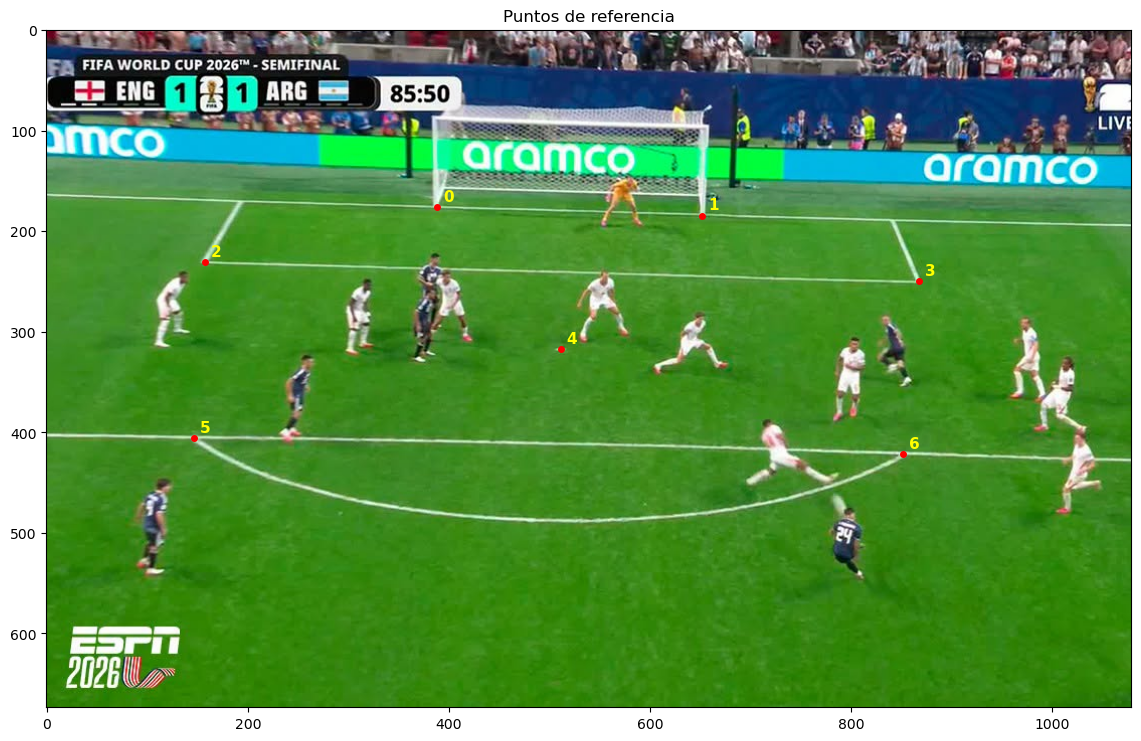

In [21]:
filepath_futbol = 'futbol'
img_gol = cv2.imread(f'{filepath_futbol}/test-gol-enzo.png')[:, :, ::-1]   # BGR -> RGB

# Puntos de referencia en la cancha (m)
objPts_gol = np.array([
    [0.0,  30.34],   # 0: palo izquierdo
    [0.0,  37.66],   # 1: palo derecho
    [5.5,  24.84],   # 2: área chica, esquina frontal izq
    [5.5,  43.16],   # 3: área chica, esquina frontal der
    [11.0, 34.0],    # 4: punto penal
    [16.5, 26.69],   # 5: medialuna ∩ línea del área, izq
    [16.5, 41.31],   # 6: medialuna ∩ línea del área, der
])

# Los mismos puntos en la foto (px)
imgPts_gol = np.array([
    [388.0, 176.0],
    [652.0, 184.5],
    [157.0, 231.0],
    [867.0, 250.0],
    [511.0, 317.0],
    [146.0, 406.0],
    [851.0, 422.0],
])

plt.figure(figsize=(14, 9))
plt.imshow(img_gol)
plt.plot(imgPts_gol[:, 0], imgPts_gol[:, 1], 'ro', markersize=4)
for i in range(imgPts_gol.shape[0]):
    plt.text(imgPts_gol[i, 0] + 6, imgPts_gol[i, 1] - 6, str(i), color='yellow', fontsize=11, weight='bold')
plt.title('Puntos de referencia')
plt.show()

**Estimación de $\mathbf{H}$.** Con las correspondencias resolvemos $Q\mathbf{h} = 0$ con $\texttt{resolverDLT2D}$ (DLT con normalización de Hartley, ejercicio 3). La $\mathbf{H}$ obtenida lleva puntos de la cancha a la imagen, y su inversa $\mathbf{H}^{-1}$ lleva puntos de la imagen a la cancha.

In [22]:
H_gol = alc.resolverDLT2D(imgPts_gol, objPts_gol)
H_gol_inv = alc.inversa(H_gol)
print(H_gol / H_gol[2, 2])

[[-9.53430586e+00  3.75647516e+01 -7.34465149e+02]
 [ 7.85950377e+00  1.32071564e+00  1.41846379e+02]
 [-1.67225462e-02  1.23844639e-03  1.00000000e+00]]


**Posición de Enzo.** Marcamos en la foto el pie de apoyo de Enzo al patear, $(u, v) = (810,\ 545)$, y lo llevamos a la cancha:

$$\begin{bmatrix} q_1 \\ q_2 \\ q_3 \end{bmatrix} = \mathbf{H}^{-1} \begin{bmatrix} 810 \\ 545 \\ 1 \end{bmatrix}, \qquad U = \frac{q_1}{q_3},\quad V = \frac{q_2}{q_3}.$$

**Distancia.** La distancia se mide respecto al arco, y el punto del arco es a elección (consultado en clase). Elegimos el punto donde entró la pelota, $(U, V) = (0,\ 31)$: sobre la línea de meta, entre los palos ($V = 30.34$ a $37.66$) y cerca del palo izquierdo. La distancia en línea recta sobre el piso es

$$d = \sqrt{(U_{enzo} - 0)^2 + (V_{enzo} - 31)^2}.$$

Enzo en la cancha: U = 22.24 m, V = 39.80 m
Distancia al arco (punto donde entró la pelota): 23.92 m


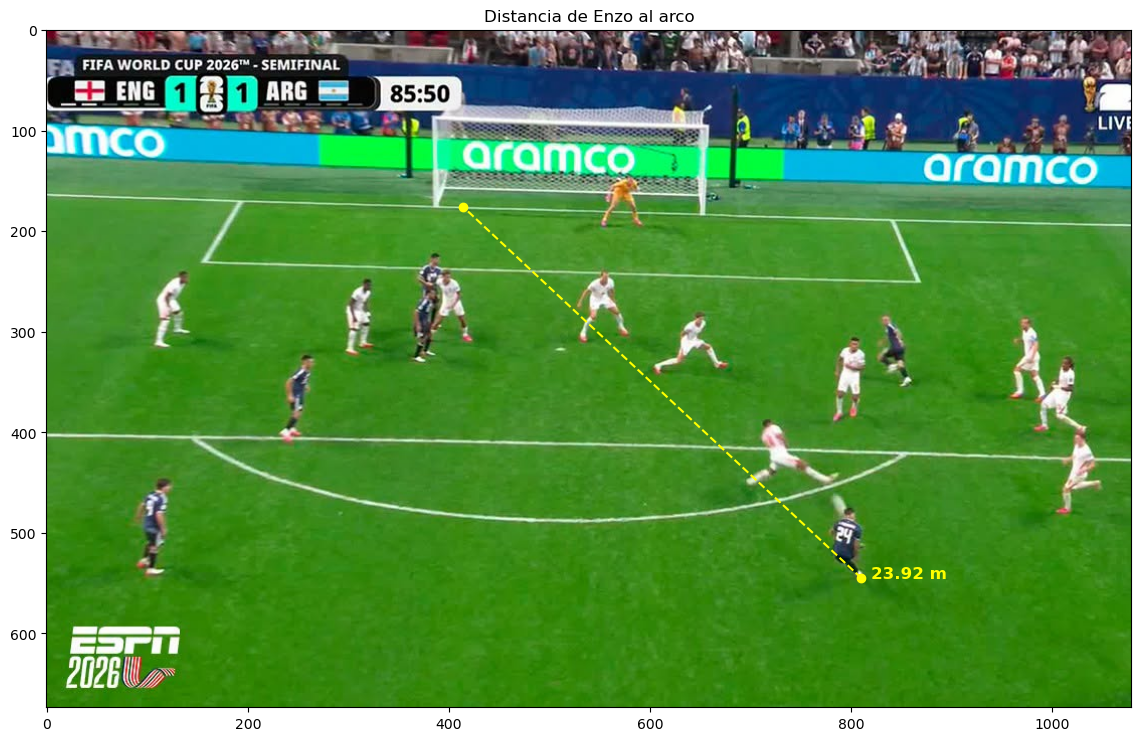

In [23]:
# Pie de apoyo de Enzo al patear (px)
pie_enzo_img = np.array([[810.0, 545.0]])
# Punto del arco donde entró la pelota (m)
punto_gol = np.array([0.0, 31.0])

U_enzo, V_enzo = alc.aplicarHomografia(H_gol_inv, pie_enzo_img)[0]
distancia = np.sqrt((U_enzo - punto_gol[0])**2 + (V_enzo - punto_gol[1])**2)
print(f'Enzo en la cancha: U = {U_enzo:.2f} m, V = {V_enzo:.2f} m')
print(f'Distancia al arco (punto donde entró la pelota): {distancia:.2f} m')

# Llevamos el punto del gol a la foto para dibujar el segmento
punto_gol_img = alc.aplicarHomografia(H_gol, np.array([punto_gol]))[0]

plt.figure(figsize=(14, 9))
plt.imshow(img_gol)
plt.plot([pie_enzo_img[0, 0], punto_gol_img[0]], [pie_enzo_img[0, 1], punto_gol_img[1]], '--o', color='yellow', linewidth=1.5, markersize=6)
plt.text(pie_enzo_img[0, 0] + 10, pie_enzo_img[0, 1], f'{distancia:.2f} m', color='yellow', fontsize=12, weight='bold')
plt.title('Distancia de Enzo al arco')
plt.show()

Enzo está en $U \approx 22.24$ m, $V \approx 39.80$ m, a $d \approx 23.92$ m del punto donde entró la pelota. El resultado es razonable: Enzo patea desde afuera del área grande ($U > 16.5$) y también por fuera de la medialuna ($U > 20.15$ en $V = 34$). Hay que tener en cuenta que el pie se marcó a mano y que Enzo está por debajo de los puntos de referencia, así que el resultado tiene una incertidumbre del orden de algunas décimas de metro.

b) Ubicar espacialmente todos los jugadores argentinos y dibujar un círculo de 1 metro de radio sobre el piso, como se muestra en la fig. 4. Para ello, definir el círculo en coordenadas de la cancha y proyectar sus puntos a la imagen mediante $\mathbf{H}$.

#### Resolución 4.b
Usamos la misma $\mathbf{H}$ del 4.a. Para cada jugador: llevamos su pie a la cancha con $\mathbf{H}^{-1}$, armamos ahí el círculo de 1 m de radio con $\texttt{circuloEnCancha}$ (sin seno ni coseno, despejando $V = V_0 \pm \sqrt{r^2 - (U - U_0)^2}$) y proyectamos sus puntos a la foto con $\mathbf{H}$.

Los pies se marcaron a mano. El jugador de atrás del grupo del medio tiene los pies tapados por su compañero, así que su posición se estimó por la bota que se ve y es la menos precisa.

Jugador 0: U = 22.53 m, V = 27.14 m
Jugador 1: U = 16.33 m, V = 28.65 m
Jugador 2: U = 9.79 m, V = 31.07 m
Jugador 3: U = 11.83 m, V = 30.94 m
Jugador 4: U = 12.59 m, V = 41.85 m
Jugador 5: U = 22.24 m, V = 39.80 m


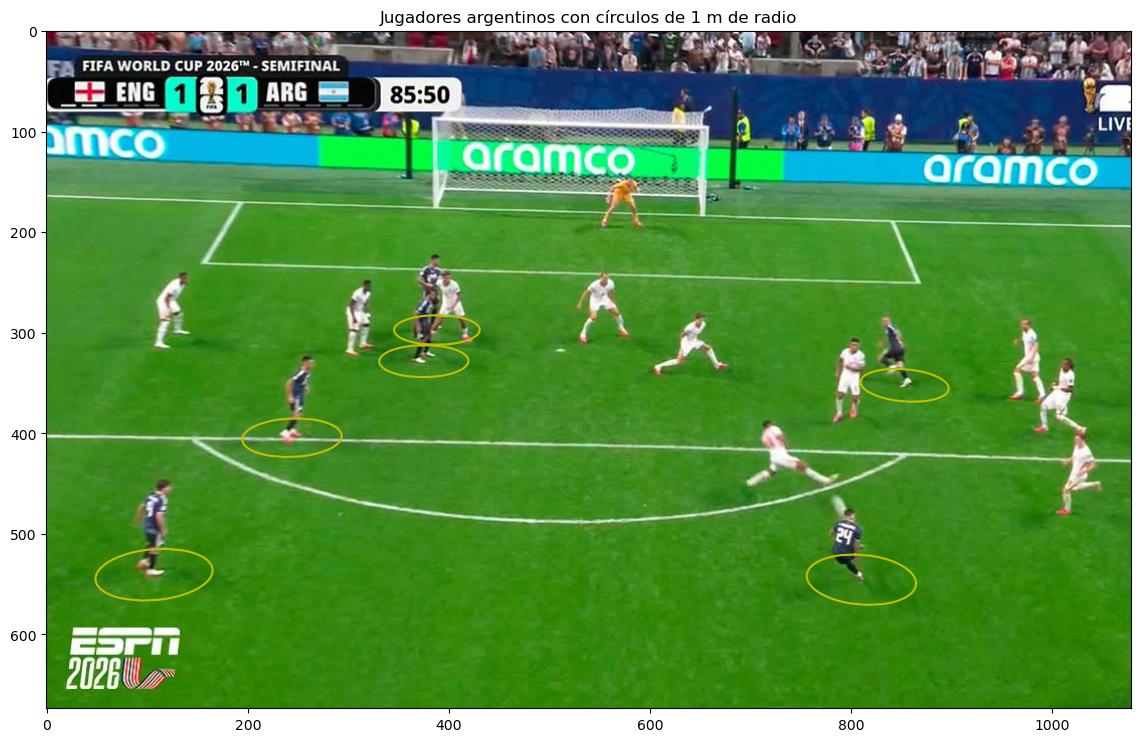

In [24]:
# Pies de los jugadores argentinos (px)
pies_argentinos_img = np.array([
    [107.0, 540.0],   # abajo a la izquierda
    [244.0, 404.0],   # sobre la línea del área
    [388.0, 297.0],   # el de atrás del grupo del medio (pies tapados, estimado)
    [375.0, 328.0],   # el de adelante del grupo del medio
    [853.0, 352.0],   # a la derecha
    [810.0, 545.0],   # Enzo
])

pies_cancha = alc.aplicarHomografia(H_gol_inv, pies_argentinos_img)
for i in range(pies_cancha.shape[0]):
    print(f'Jugador {i}: U = {pies_cancha[i, 0]:.2f} m, V = {pies_cancha[i, 1]:.2f} m')

plt.figure(figsize=(14, 9))
plt.imshow(img_gol)
for i in range(pies_cancha.shape[0]):
    circulo_img = alc.aplicarHomografia(H_gol, alc.circuloEnCancha(pies_cancha[i], 1.0, 50))
    plt.plot(circulo_img[:, 0], circulo_img[:, 1], 'y-', linewidth=1.5)
plt.title('Jugadores argentinos con círculos de 1 m de radio')
plt.show()

En la foto los círculos se ven como elipses por la perspectiva. El jugador que está sobre la línea del área (jugador 1) da $U \approx 16.33$ m, muy cerca del valor real $16.5$ m, lo que confirma que $\mathbf{H}$ funciona bien también fuera de los puntos de referencia.

Para la foto $\texttt{posibleoffside.jpg}$, estimar su propia homografía $\mathbf{H}$ y utilizarla para:

c) Trazar una recta paralela a la línea de fondo de la cancha que toque el pie del último defensor (es decir, el penúltimo jugador adversario, contando al arquero) para determinar si los jugadores de blanco estaban en fuera de juego. La recta se define en coordenadas de la cancha y se proyecta a la imagen mediante $\mathbf{H}$.

#### Resolución 4.c
Es otra foto (otra cámara), así que estimamos una homografía nueva $\mathbf{H}$ con puntos de esta imagen. Usamos el mismo sistema de coordenadas del plano: los de blanco atacan el arco de $U = 105$ (a la derecha de la foto) y la banda de arriba de la foto es $V = 68$.

Puntos de referencia: el córner $(105, 68)$, las esquinas del área grande sobre la línea del área $(88.5,\ 34 \pm 20.16)$, las esquinas frontales del área chica $(99.5,\ 34 \pm 9.16)$, el punto penal $(94, 34)$ y el corte de abajo de la medialuna con la línea del área $(88.5,\ 26.69)$. El corte de arriba está tapado por jugadores.

In [25]:
img_offside = cv2.imread(f'{filepath_futbol}/test-fuera-de-juego.png')[:, :, ::-1]   # BGR -> RGB

# Puntos de referencia en la cancha (m)
objPts_offside = np.array([
    [105.0, 68.0],    # 0: córner (banderín)
    [88.5,  54.16],   # 1: área grande, esquina de arriba sobre la línea del área
    [88.5,  13.84],   # 2: área grande, esquina de abajo sobre la línea del área
    [99.5,  43.16],   # 3: área chica, esquina frontal de arriba
    [99.5,  24.84],   # 4: área chica, esquina frontal de abajo
    [94.0,  34.0],    # 5: punto penal
    [88.5,  26.69],   # 6: medialuna ∩ línea del área, abajo
])

# Los mismos puntos en la foto (px)
imgPts_offside = np.array([
    [1306.0, 237.0],
    [736.0,  317.0],
    [735.5,  756.5],
    [1230.0, 390.0],
    [1365.0, 576.0],
    [1008.0, 474.0],
    [734.0,  557.0],
])

H_off = alc.resolverDLT2D(imgPts_offside, objPts_offside)
H_off_inv = alc.inversa(H_off)
print(H_off / H_off[2, 2])

[[ 8.86025000e+01  1.75955987e+01 -7.13755268e+03]
 [-9.39970587e-01 -6.46638181e+00  1.14738139e+03]
 [-4.25812863e-04  2.38092477e-02  1.00000000e+00]]


**Último defensor.** Llevamos a la cancha con $\mathbf{H}^{-1}$ el pie más adelantado (hacia el arco) de cada defensor. El último defensor es el penúltimo contando al arquero: el de mayor $U$ sin contar al arquero, que es el de mayor $U$ de todos.

In [26]:
# Pie más adelantado de cada defensor (px)
pies_defensores_img = np.array([
    [1432.0, 467.0],  # arquero
    [824.0,  331.0],  # el de arriba del grupo
    [767.0,  370.0],  # el del medio del grupo
    [770.0,  535.0],  # el 5
    [813.0,  560.0],  # el 22
])

U_defensores = alc.aplicarHomografia(H_off_inv, pies_defensores_img)[:, 0]

# El arquero es el de mayor U; el último defensor, el de mayor U entre los demás
i_arquero = 0
for i in range(U_defensores.shape[0]):
    if U_defensores[i] > U_defensores[i_arquero]:
        i_arquero = i
i_ultimo = -1
for i in range(U_defensores.shape[0]):
    if i != i_arquero and (i_ultimo == -1 or U_defensores[i] > U_defensores[i_ultimo]):
        i_ultimo = i
U_ultimo = U_defensores[i_ultimo]
for i in range(U_defensores.shape[0]):
    print(f'Defensor {i}: U = {U_defensores[i]:.2f} m')
print(f'Último defensor: {i_ultimo}, U = {U_ultimo:.2f} m')

Defensor 0: U = 102.42 m
Defensor 1: U = 90.68 m
Defensor 2: U = 89.23 m
Defensor 3: U = 89.16 m
Defensor 4: U = 89.91 m
Último defensor: 1, U = 90.68 m


**Atacantes y recta del último defensor.** Un atacante está adelantado si su pie tiene $U$ mayor que el del último defensor. La recta paralela a la línea de fondo es $U = U_{\text{último}}$; la definimos en la cancha y la proyectamos con $\mathbf{H}$.

Atacante 0: U = 89.83 m, diferencia = -0.85 m -> habilitado
Atacante 1: U = 89.55 m, diferencia = -1.13 m -> habilitado
Atacante 2: U = 90.24 m, diferencia = -0.44 m -> habilitado
Atacante 3: U = 91.00 m, diferencia = +0.32 m -> ADELANTADO
Atacante 4: U = 90.87 m, diferencia = +0.19 m -> ADELANTADO


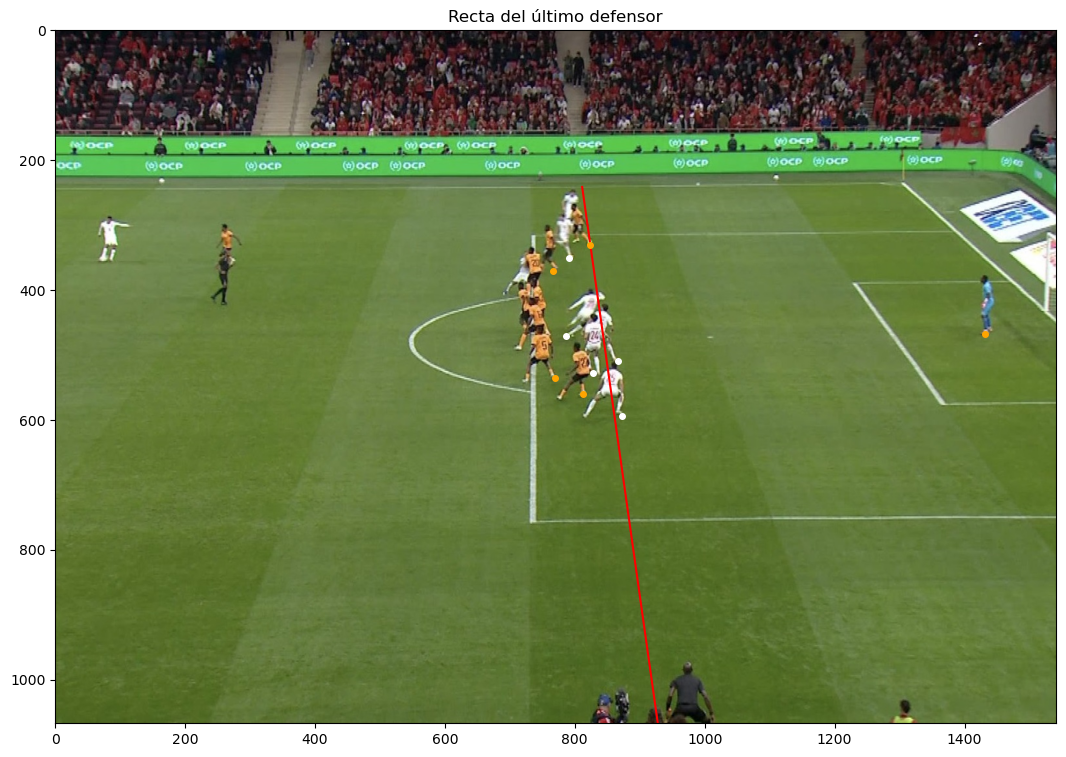

In [27]:
# Pie más adelantado de cada atacante (px)
pies_atacantes_img = np.array([
    [791.0, 350.0],   # el de arriba del grupo
    [787.0, 470.0],   # el del medio
    [828.0, 528.0],   # el 24
    [866.0, 509.0],   # el que está a la derecha del 24 (pie posiblemente en el aire)
    [872.0, 594.0],   # el 25
])

U_atacantes = alc.aplicarHomografia(H_off_inv, pies_atacantes_img)[:, 0]
for i in range(U_atacantes.shape[0]):
    diferencia = U_atacantes[i] - U_ultimo
    estado = 'ADELANTADO' if diferencia > 0 else 'habilitado'
    print(f'Atacante {i}: U = {U_atacantes[i]:.2f} m, diferencia = {diferencia:+.2f} m -> {estado}')

recta_img = alc.aplicarHomografia(H_off, np.array([[U_ultimo, 0.0], [U_ultimo, 68.0]]))

plt.figure(figsize=(14, 9))
plt.imshow(img_offside)
plt.plot(recta_img[:, 0], recta_img[:, 1], 'r-', linewidth=1.5)
plt.plot(pies_defensores_img[:, 0], pies_defensores_img[:, 1], 'o', color='orange', markersize=4)
plt.plot(pies_atacantes_img[:, 0], pies_atacantes_img[:, 1], 'wo', markersize=4)
plt.xlim(0, img_offside.shape[1])
plt.ylim(img_offside.shape[0], 0)
plt.title('Recta del último defensor')
plt.show()

**Conclusión.** El último defensor es el de arriba del grupo ($U \approx 90.68$ m). Dos atacantes quedan por delante de la recta: el que está a la derecha del 24 ($+0.32$ m) y el 25 ($+0.19$ m), así que **hay fuera de juego**. La pelota está muy atrás (la tiene el jugador de la izquierda), así que esa condición también se cumple.

La jugada es muy ajustada: las diferencias son de unos pocos decímetros, del mismo orden que el error de marcar los pies a mano. Además, el pie del atacante a la derecha del 24 parece estar en el aire, y $\mathbf{H}$ solo vale para puntos sobre el piso.

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

**Resultados de la aplicación de POSIT**:
Aplicamos el algoritmo POSIT para puntos coplanares, utilizando las correspondencias entre los cinco puntos 3D de la H y sus posiciones 2D en la fotografía, junto con la matriz intrínseca (K) de la cámara,que tenemos como dato.
Con este algoritmo pudimos estimar la pose de la cámara respecto del sistema de coordenadas de la H, y obtuvimos la matriz de rotación (R) y el vector de traslación (t).
Para evaluar la pose estimada, proyectamos nuevamente, utilizando R,t,K, los puntos 3D sobre el plano imagen y calculamos el RMSE respecto de las coordenadas 2D observadas.

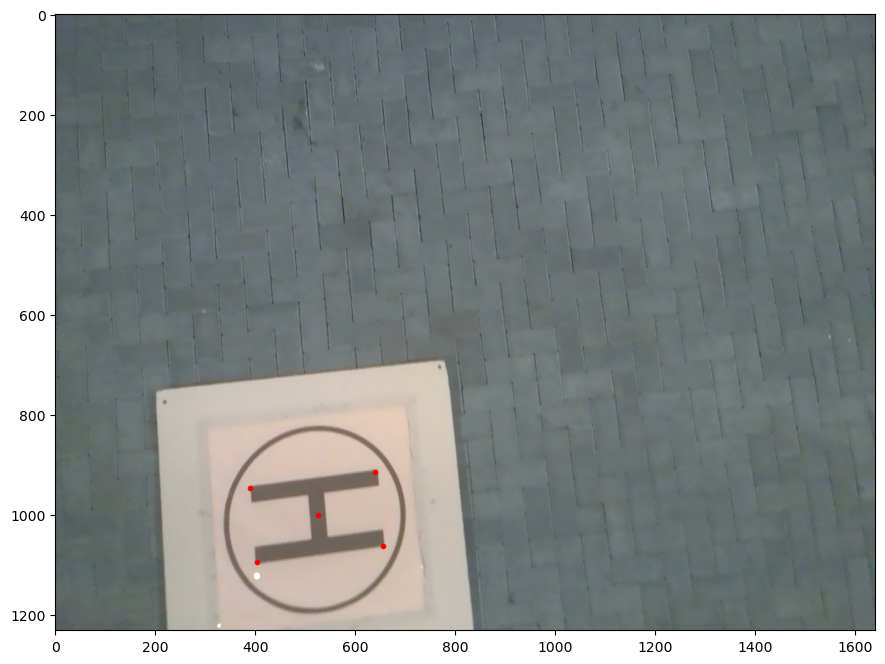

In [28]:
filepath_base = 'heli'
matriz_K = pd.read_csv(f'{filepath_base}/K.csv', sep=';', header=None).to_numpy()
puntos_3d = pd.read_csv(f'{filepath_base}/object_points.csv', sep=';', header=0, index_col=0).to_numpy(dtype=float)

#ejercicio 6.a:
# Aplicamos la versión de POSIT para puntos coplanares,ya que los cinco puntos dados pertenecen al plano UV (W = 0).

filename = f'{filepath_base}/row_00248.png'
rgb = cv2.imread(filename)

plt.figure(figsize=(12,8), dpi=100)
plt.imshow(rgb)

centro =  (525,1000)
esq_sup_izq = (403,1095)
esq_sup_der = (390,947)
esq_inf_der = (640,915)
esq_inf_izq = (656,1063)

plt.plot(centro[0], centro[1],'ro', markersize=3)
plt.plot(esq_sup_izq[0], esq_sup_izq[1],'ro', markersize=3)
plt.plot(esq_sup_der[0], esq_sup_der[1],'ro', markersize=3)
plt.plot(esq_inf_der[0], esq_inf_der[1],'ro', markersize=3)
plt.plot(esq_inf_izq[0], esq_inf_izq[1],'ro', markersize=3)

plt.show()


---

In [54]:
#estimamos R y t
puntos_2d = np.array([
    [525, 1000],  #Centro M0
    [403, 1095],  #Superior izquierdo
    [390, 947],   #Superior derecho
    [640, 915],   #Inferior derecho
    [656, 1063]   #Inferior izquierdo
])
        
MaxIt=100
atol=1e-8
R,t=alc.aplicarPOSIT(puntos_3d, puntos_2d, matriz_K, MaxIt, atol)
print("Matriz de rotación (R): ", R)
print("Chequeamos que es R es efectivamente una matriz de rotación, es decir que det(R) ≈ 1 y RᵀR ≈ I")
print("Determinante(R):", alc.determinante_3x3(R))
print("¿Es aproximadamente 1?")
print(alc.error(alc.determinante_3x3(R),1)<atol)
producto = alc.multiplicar(alc.traspuesta(R), R)
print("R traspuesta por R:")
print(producto)
print("¿Es aproximadamente la identidad?")
print(alc.matricesIguales(producto,np.eye(3)))
print("Vector de traslación (t):", t)
print("Chequeamos que la pose sea válida, y el error de reproyección(RMSE)")
validos, error = alc.evaluarPose(R, t, puntos_3d, puntos_2d, matriz_K)
print("Puntos válidos:", validos)
print("RMSE:", error)

Matriz de rotación (R):  [[-0.13327043 -0.960791    0.2431453 ]
 [-0.96718355  0.07253377 -0.24350531]
 [ 0.21632146 -0.2676182  -0.93892786]]
Chequeamos que es R es efectivamente una matriz de rotación, es decir que det(R) ≈ 1 y RᵀR ≈ I
Determinante(R): 0.9999999999999999
¿Es aproximadamente 1?
True
R traspuesta por R:
[[ 1.0000000e+00 -6.9388939e-18  0.0000000e+00]
 [-6.9388939e-18  1.0000000e+00  0.0000000e+00]
 [ 0.0000000e+00  0.0000000e+00  1.0000000e+00]]
¿Es aproximadamente la identidad?
True
Vector de traslación (t): [-0.70459824  0.91992538  4.52880818]
Chequeamos que la pose sea válida, y el error de reproyección(RMSE)
Puntos válidos: 5
RMSE: 2.2393522931427197


A continuación, podemos observar en un gráfico, la pequeña diferencia entre las posiciones 2D originales de los puntos y las obtenidas al proyectarlos utilizando la pose estimada por POSIT.

In [ ]:
# proyectamos los puntos 3D utilizando la pose estimada por POSIT
puntos_proyectados = []

for punto in puntos_3d:
    coords_camara = alc.calcularAx(R, punto) + t
    proyeccion = alc.calcularAx(matriz_K, coords_camara)

    u = proyeccion[0] / proyeccion[2]
    v = proyeccion[1] / proyeccion[2]

    puntos_proyectados.append([u, v])

puntos_proyectados = np.array(puntos_proyectados)

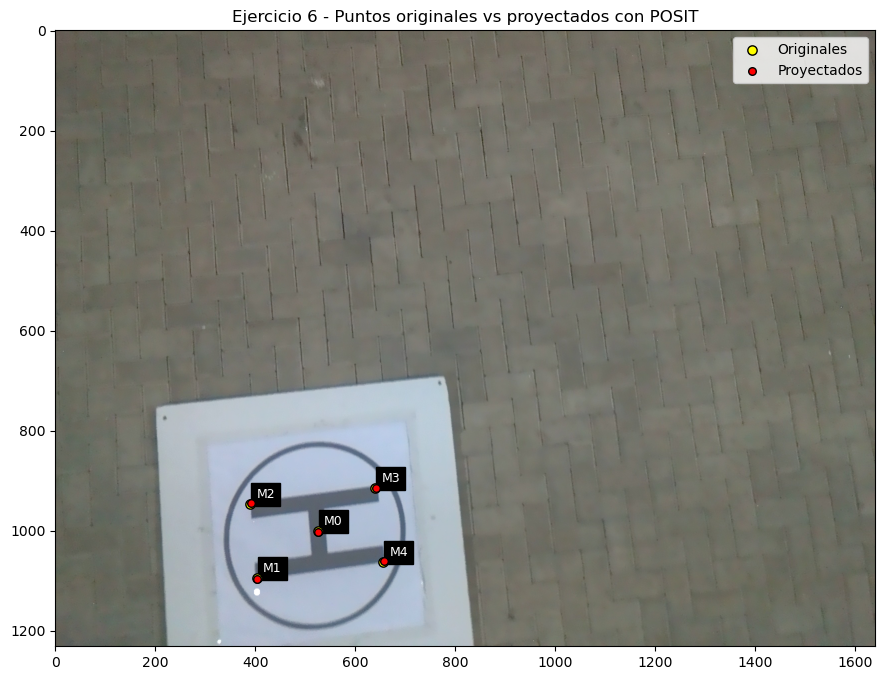

In [51]:
def comparar_puntos_y_mostrar(img, pts_originales, pts_proyectados):
    """
    Muestra sobre la imagen los puntos 2D observados y
    los proyectados mediante la pose estimada por POSIT.
    """
    etiquetas = ["M0", "M1", "M2", "M3", "M4"]

    plt.figure(figsize=(12, 8))
    plt.imshow(img[:, :, ::-1])

    plt.scatter(
        pts_originales[:, 0], pts_originales[:, 1],
        s=45, c="yellow", edgecolors="black",
        label="Originales", zorder=4
    )

    plt.scatter(
        pts_proyectados[:, 0], pts_proyectados[:, 1],
        s=30, c="red", edgecolors="black",
        label="Proyectados", zorder=5
    )

    for (u, v), etiqueta in zip(pts_originales, etiquetas):
        plt.text(
            u + 12, v - 12, etiqueta,
            color="white", backgroundcolor="black",
            fontsize=9
        )

    plt.title("Ejercicio 6 - Puntos originales vs proyectados con POSIT")
    plt.legend()
    plt.show()

comparar_puntos_y_mostrar(rgb, puntos_2d, puntos_proyectados)

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

Para que la cámara observe la letra H de manera vertical, debemos determinar una nueva matriz de rotación $R$.
Como los puntos de la H pertenecen al plano $UV$, dado que todos tienen $W=0$, el eje óptico de la cámara debe ser perpendicular a dicho plano.
Además, tenemos que considerar el punto blanco, que señala la esquina superior izquierda de la H y nos ayuda a determinar cómo debe quedar orientada la imagen.
La matriz de rotación se construye a partir de los vectores unitarios y mutuamente ortogonales $i$, $j$ y $k$, que forman una base ortonormal (BON):

$$
R=\begin{pmatrix}
i^T\\
j^T\\
k^T
\end{pmatrix},
\qquad k=i\times j
$$

Para determinar la matriz de rotación, vamos a considerar las coordenadas 3D de los puntos de H, en particular tendremos
en cuenta los puntos: 

$M_0=(0,0,0)$ (centro de la H) y $M_1=(-0.175,0.3,0)$ (punto más cercano al punto blanco en la esquina superior izquierda de la H)

En la foto original, $M_1$ aparece a la izquierda y debajo de $M_0$, ya que sus coordenadas 2D son:

$$
m_0=(525,1000),\qquad m_1=(403,1095)
$$


Para la nueva pose queremos que $M_1$ aparezca arriba a la izquierda de $M_0$.
Partiendo de la siguiente ecuación:

$$
\begin{pmatrix}
X\\
Y\\
Z
\end{pmatrix}
=
R
\begin{pmatrix}
U\\
V\\
W
\end{pmatrix}
+t
$$

Como las coordenadas de la imagen aumentan hacia la derecha y hacia abajo, buscamos que $M_1$ tenga $X_1<0$ e $Y_1<0$ en el sistema de la nueva cámara, tomando como referencia el centro $M_0$.

Entonces, si tomamos

$$
i=(1,0,0)
$$

para que la dirección horizontal positiva de $U$ se proyecte hacia la derecha, y así logramos que $M_1$, que tiene $U_1<0$, aparezca a la izquierda.

También elegimos:

$$
j=(0,-1,0)
$$

porque queremos que $M_1$, cuya coordenada $V_1=0.3$ es positiva, aparezca por encima de $M_0$ en la imagen. Como la coordenada vertical de la imagen aumenta hacia abajo, necesitamos que su coordenada $Y_1$ respecto de la cámara sea negativa.

Como queremos que $M_0$ quede sobre el eje óptico, tomamos $t_x=t_y=0$. Entonces:

$$
X=U,\qquad Y=-V
$$

Finalmente, calculamos:

$$
k=i\times j=(0,0,-1)
$$

Este vector es perpendicular al plano $UV$ y apunta hacia abajo, suponiendo que el eje $W$ positivo apunta hacia arriba.

Por lo tanto, la matriz de rotación que nos sirve es:

$$
R=
\begin{pmatrix}
1&0&0\\
0&-1&0\\
0&0&-1
\end{pmatrix}
$$

Y esta matriz cumple las condiciones de una matriz de rotación:

$$
R^TR=I,\qquad \det(R)=1
$$

Respecto al vector de traslación t, si buscamos ubicar el dron exactamente sobre el centro de la H, queremos que $M_0$ quede sobre el eje óptico de la cámara, a una profundidad $h>0$ , que representaría la altura a la que se encunetra el dron.

Utilizamos la ecuación:

$$
RM_0+t=
\begin{pmatrix}
0\\
0\\
h
\end{pmatrix}
$$

Como $M_0=(0,0,0)$, obtenemos:

$$
t=
\begin{pmatrix}
0\\
0\\
h
\end{pmatrix}
$$


Finalmente, la pose de la cámara que cumple las condiciones está dada por:

$$
\boxed{
R=
\begin{pmatrix}
1&0&0\\
0&-1&0\\
0&0&-1
\end{pmatrix},
\qquad
t=
\begin{pmatrix}
0\\
0\\
h
\end{pmatrix},
\quad h>0
}
$$

